In [12]:
!pip install  xlrd

In [17]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.feature_selection import SelectKBest, f_classif

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")

In [16]:
import pandas as pd

data = pd.read_excel("Customer Churn.xls")

print(data.head())

   Call  Failure  Complains  Subscription  Length  Charge  Amount  \
0              8          0                    38               0   
1              0          0                    39               0   
2             10          0                    37               0   
3             10          0                    38               0   
4              3          0                    38               0   

   Seconds of Use  Frequency of use  Frequency of SMS  \
0            4370                71                 5   
1             318                 5                 7   
2            2453                60               359   
3            4198                66                 1   
4            2393                58                 2   

   Distinct Called Numbers  Age Group  Tariff Plan  Status  Age  \
0                       17          3            1       1   30   
1                        4          2            1       2   25   
2                       24          3    

In [18]:
df=pd.DataFrame(data)

In [19]:
df

,Call Failure,Complains,Subscription Length,Charge Amount,Seconds of Use,Frequency of use,Frequency of SMS,Distinct Called Numbers,Age Group,Tariff Plan,Status,Age,Customer Value,Churn
0,8,0,38,0,4370,71,5,17,3,1,1,30,197.640,0
1,0,0,39,0,318,5,7,4,2,1,2,25,46.035,0
2,10,0,37,0,2453,60,359,24,3,1,1,30,1536.520,0
3,10,0,38,0,4198,66,1,35,1,1,1,15,240.020,0
4,3,0,38,0,2393,58,2,33,1,1,1,15,145.805,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3145,21,0,19,2,6697,147,92,44,2,2,1,25,721.980,0
3146,17,0,17,1,9237,177,80,42,5,1,1,55,261.210,0
3147,13,0,18,4,3157,51,38,21,3,1,1,30,280.320,0
3148,7,0,11,2,4695,46,222,12,3,1,1,30,1077.640,0


In [20]:
df.head(5)


,Call Failure,Complains,Subscription Length,Charge Amount,Seconds of Use,Frequency of use,Frequency of SMS,Distinct Called Numbers,Age Group,Tariff Plan,Status,Age,Customer Value,Churn
0,8,0,38,0,4370,71,5,17,3,1,1,30,197.640,0
1,0,0,39,0,318,5,7,4,2,1,2,25,46.035,0
2,10,0,37,0,2453,60,359,24,3,1,1,30,1536.520,0
3,10,0,38,0,4198,66,1,35,1,1,1,15,240.020,0
4,3,0,38,0,2393,58,2,33,1,1,1,15,145.805,0


In [21]:
df.tail(2)

,Call Failure,Complains,Subscription Length,Charge Amount,Seconds of Use,Frequency of use,Frequency of SMS,Distinct Called Numbers,Age Group,Tariff Plan,Status,Age,Customer Value,Churn
3148,7,0,11,2,4695,46,222,12,3,1,1,30,1077.64,0
3149,8,1,11,2,1792,25,7,9,3,1,1,30,100.68,1


In [22]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 3150 entries, 0 to 3149
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Call  Failure            3150 non-null   int64  
 1   Complains                3150 non-null   int64  
 2   Subscription  Length     3150 non-null   int64  
 3   Charge  Amount           3150 non-null   int64  
 4   Seconds of Use           3150 non-null   int64  
 5   Frequency of use         3150 non-null   int64  
 6   Frequency of SMS         3150 non-null   int64  
 7   Distinct Called Numbers  3150 non-null   int64  
 8   Age Group                3150 non-null   int64  
 9   Tariff Plan              3150 non-null   int64  
 10  Status                   3150 non-null   int64  
 11  Age                      3150 non-null   int64  
 12  Customer Value           3150 non-null   float64
 13  Churn                    3150 non-null   int64  
dtypes: float64(1), int64(13)
memory usa

In [23]:
df.columns

Index(['Call  Failure', 'Complains', 'Subscription  Length', 'Charge  Amount',
       'Seconds of Use', 'Frequency of use', 'Frequency of SMS',
       'Distinct Called Numbers', 'Age Group', 'Tariff Plan', 'Status', 'Age',
       'Customer Value', 'Churn'],
      dtype='str')

In [24]:
df.describe

<bound method NDFrame.describe of       Call  Failure  Complains  Subscription  Length  Charge  Amount  \
0                 8          0                    38               0   
1                 0          0                    39               0   
2                10          0                    37               0   
3                10          0                    38               0   
4                 3          0                    38               0   
...             ...        ...                   ...             ...   
3145             21          0                    19               2   
3146             17          0                    17               1   
3147             13          0                    18               4   
3148              7          0                    11               2   
3149              8          1                    11               2   

      Seconds of Use  Frequency of use  Frequency of SMS  \
0               4370                71   

In [25]:
#remove the extra index column if present
df=df.drop(columns=[""],errors="ignore")
df=df.loc[:,~df.columns.str.match(r"^Unnamed")]

In [26]:
#convert cols to numv=eric where possible
for col in df.columns:
    df[col]=pd.to_numeric(df[col],errors="coerce")

In [27]:
df.head(4)

,Call Failure,Complains,Subscription Length,Charge Amount,Seconds of Use,Frequency of use,Frequency of SMS,Distinct Called Numbers,Age Group,Tariff Plan,Status,Age,Customer Value,Churn
0,8,0,38,0,4370,71,5,17,3,1,1,30,197.640,0
1,0,0,39,0,318,5,7,4,2,1,2,25,46.035,0
2,10,0,37,0,2453,60,359,24,3,1,1,30,1536.520,0
3,10,0,38,0,4198,66,1,35,1,1,1,15,240.020,0


In [28]:
df.isnull().sum()

Call  Failure              0
Complains                  0
Subscription  Length       0
Charge  Amount             0
Seconds of Use             0
Frequency of use           0
Frequency of SMS           0
Distinct Called Numbers    0
Age Group                  0
Tariff Plan                0
Status                     0
Age                        0
Customer Value             0
Churn                      0
dtype: int64

In [29]:
df.duplicated()

0       False
1       False
2       False
3       False
4       False
        ...  
3145     True
3146     True
3147     True
3148     True
3149     True
Length: 3150, dtype: bool

<Axes: >

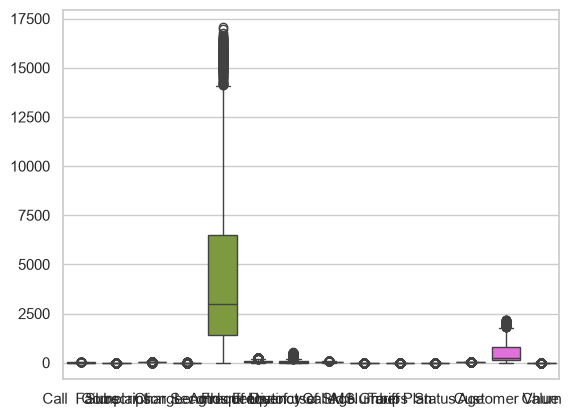

In [32]:
sns.boxplot(data=df)

In [34]:
#Function to apply IQR method to fix outliers
def fix_outliers_iqr(df):
    num=df.select_dtypes(include='number').columns
    for col in num:
        Q1 = df[col].quantile(0.25)
        Q3 = df[col].quantile(0.75)
        IQR = Q3 - Q1
        lower_bound = Q1 - 1.5 * IQR
        upper_bound = Q3 + 1.5 * IQR
# Replace outliers with the respective bounds
        df[col] = df[col].apply(lambda x: lower_bound if x < lower_bound else upper_bound if x > upper_bound else x)
    return df

In [35]:
print(df.columns.tolist())

['Call  Failure', 'Complains', 'Subscription  Length', 'Charge  Amount', 'Seconds of Use', 'Frequency of use', 'Frequency of SMS', 'Distinct Called Numbers', 'Age Group', 'Tariff Plan', 'Status', 'Age', 'Customer Value', 'Churn']


In [36]:
df.columns = df.columns.astype(str).str.strip()
print(df.columns.tolist())

['Call  Failure', 'Complains', 'Subscription  Length', 'Charge  Amount', 'Seconds of Use', 'Frequency of use', 'Frequency of SMS', 'Distinct Called Numbers', 'Age Group', 'Tariff Plan', 'Status', 'Age', 'Customer Value', 'Churn']


In [38]:
print('Status' in df.columns)

True


In [39]:
print(df.head())
print(df.shape)

   Call  Failure  Complains  Subscription  Length  Charge  Amount  \
0              8          0                    38               0   
1              0          0                    39               0   
2             10          0                    37               0   
3             10          0                    38               0   
4              3          0                    38               0   

   Seconds of Use  Frequency of use  Frequency of SMS  \
0            4370                71                 5   
1             318                 5                 7   
2            2453                60               359   
3            4198                66                 1   
4            2393                58                 2   

   Distinct Called Numbers  Age Group  Tariff Plan  Status  Age  \
0                       17          3            1       1   30   
1                        4          2            1       2   25   
2                       24          3    

In [42]:
df=pd.read_excel("Customer Churn.xls",header=None)
print(df.head())
print(df.shape)

              0          1                     2               3   \
0  Call  Failure  Complains  Subscription  Length  Charge  Amount   
1              8          0                    38               0   
2              0          0                    39               0   
3             10          0                    37               0   
4             10          0                    38               0   

               4                 5                 6   \
0  Seconds of Use  Frequency of use  Frequency of SMS   
1            4370                71                 5   
2             318                 5                 7   
3            2453                60               359   
4            4198                66                 1   

                        7          8            9       10   11  \
0  Distinct Called Numbers  Age Group  Tariff Plan  Status  Age   
1                       17          3            1       1   30   
2                        4          2    

In [44]:
df=pd.read_excel("Customer Churn.xls")

In [45]:
data

,Call Failure,Complains,Subscription Length,Charge Amount,Seconds of Use,Frequency of use,Frequency of SMS,Distinct Called Numbers,Age Group,Tariff Plan,Status,Age,Customer Value,Churn
0,8,0,38,0,4370,71,5,17,3,1,1,30,197.640,0
1,0,0,39,0,318,5,7,4,2,1,2,25,46.035,0
2,10,0,37,0,2453,60,359,24,3,1,1,30,1536.520,0
3,10,0,38,0,4198,66,1,35,1,1,1,15,240.020,0
4,3,0,38,0,2393,58,2,33,1,1,1,15,145.805,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3145,21,0,19,2,6697,147,92,44,2,2,1,25,721.980,0
3146,17,0,17,1,9237,177,80,42,5,1,1,55,261.210,0
3147,13,0,18,4,3157,51,38,21,3,1,1,30,280.320,0
3148,7,0,11,2,4695,46,222,12,3,1,1,30,1077.640,0


In [47]:
import pandas as pd
df=pd.read_excel("Customer Churn.xls",header=None)
print(df.shape)

(3151, 14)


In [48]:
df.columns = [
    'Call Failure',
    'Complains',
    'Subscription Length',
    'Charge Amount',
    'Seconds of Use',
    'Frequency of use',
    'Frequency of SMS',
    'Distinct Called Numbers',
    'Age Group',
    'Tariff Plan',
    'Status',
    'Age',
    'Customer Value',
    'Churn'
]

print(df.head())

    Call Failure  Complains   Subscription Length   Charge Amount  \
0  Call  Failure  Complains  Subscription  Length  Charge  Amount   
1              8          0                    38               0   
2              0          0                    39               0   
3             10          0                    37               0   
4             10          0                    38               0   

   Seconds of Use  Frequency of use  Frequency of SMS  \
0  Seconds of Use  Frequency of use  Frequency of SMS   
1            4370                71                 5   
2             318                 5                 7   
3            2453                60               359   
4            4198                66                 1   

   Distinct Called Numbers  Age Group  Tariff Plan  Status  Age  \
0  Distinct Called Numbers  Age Group  Tariff Plan  Status  Age   
1                       17          3            1       1   30   
2                        4          2    

Dataset loaded successfully!
   Call Failure  Complains  Subscription Length  Charge Amount  \
0             8          0                   38              0   
1             0          0                   39              0   
2            10          0                   37              0   
3            10          0                   38              0   
4             3          0                   38              0   

   Seconds of Use  Frequency of use  Frequency of SMS  \
0            4370                71                 5   
1             318                 5                 7   
2            2453                60               359   
3            4198                66                 1   
4            2393                58                 2   

   Distinct Called Numbers  Age Group  Tariff Plan  Status  Age  \
0                       17          3            1       1   30   
1                        4          2            1       2   25   
2                       24    

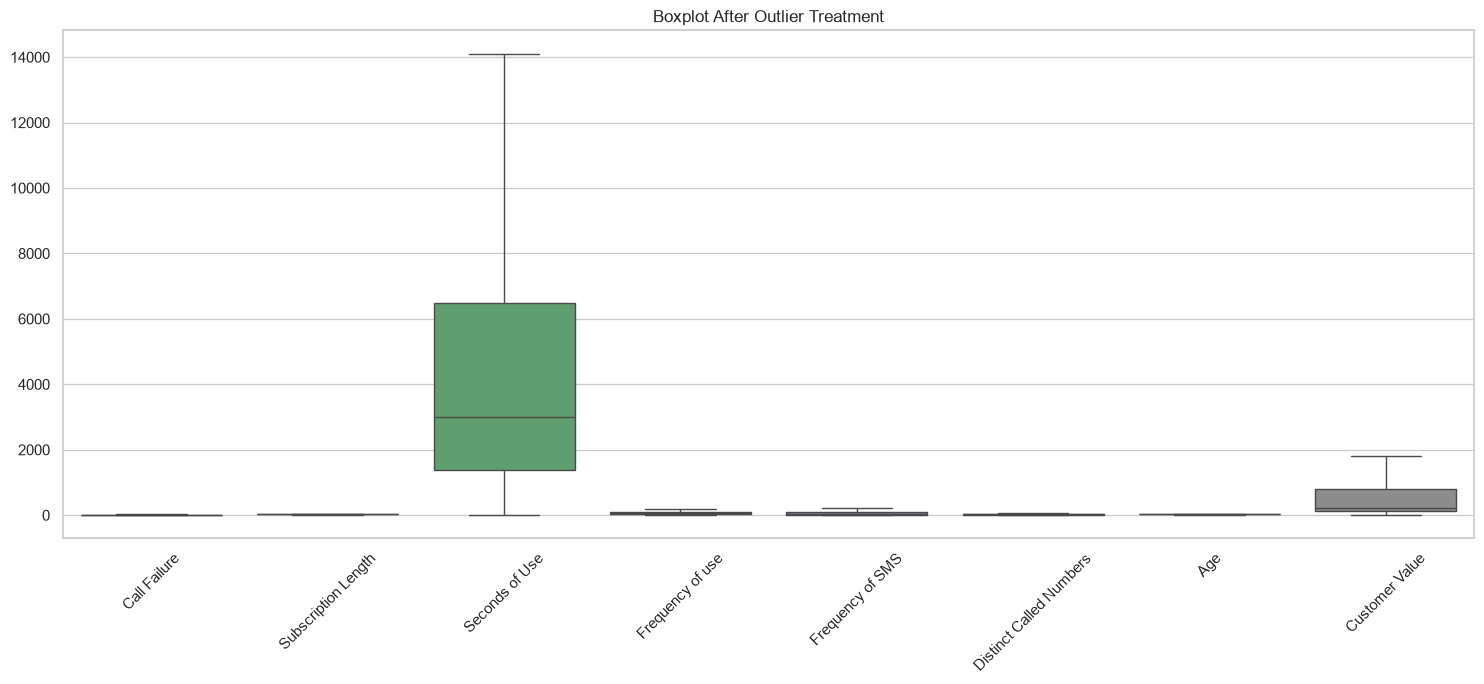

In [49]:
df = pd.read_excel("Customer Churn.xls")
df.columns = df.columns.str.strip().str.replace(r'\s+', ' ', regex=True)
print("Dataset loaded successfully!")
print(df.head())

# Step 3: Select numerical features
num_cols = [
    'Call Failure',
    'Subscription Length',
    'Seconds of Use',
    'Frequency of use',
    'Frequency of SMS',
    'Distinct Called Numbers',
    'Age',
    'Customer Value'
]

# Step 4: Convert columns into numeric data types
for col in num_cols:
    df[col] = pd.to_numeric(
        df[col].astype(str), errors='coerce'
    ).astype('float64')

print("Data types converted successfully!")
print(df[num_cols].dtypes)

# Step 5: Apply IQR method
def fix_outliers_iqr(df, columns):
    df = df.copy()

    for col in columns:
        Q1 = df[col].quantile(0.25)
        Q3 = df[col].quantile(0.75)

        IQR = Q3 - Q1

        lower = Q1 - 1.5 * IQR
        upper = Q3 + 1.5 * IQR

        df[col] = df[col].clip(lower, upper)

    return df

# Step 6: Handle outliers
df = fix_outliers_iqr(df, num_cols)

print("Outlier treatment completed!")
print("Dataset shape:", df.shape)

# Step 7: Plot boxplot
plt.figure(figsize=(15, 7))

sns.boxplot(data=df[num_cols], showfliers=False)

plt.title("Boxplot After Outlier Treatment")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [50]:
target_column = "Churn"

# Categorical columns represented by numeric category codes in this dataset.
categorical_columns = [
    column for column in [
        "Complains",
        "Age Group",
        "Tariff Plan",
        "Status"
    ]
    if column in df.columns
]

print("Target column:", target_column)
print("Categorical predictor columns:", categorical_columns)

Target column: Churn
Categorical predictor columns: ['Complains', 'Age Group', 'Tariff Plan', 'Status']


In [51]:
print(df.columns.tolist())

['Call Failure', 'Complains', 'Subscription Length', 'Charge Amount', 'Seconds of Use', 'Frequency of use', 'Frequency of SMS', 'Distinct Called Numbers', 'Age Group', 'Tariff Plan', 'Status', 'Age', 'Customer Value', 'Churn']


In [66]:
# Convert target column values into numeric format

df[target_column] = (
    df[target_column]
    .astype(str)
    .str.strip()
    .str.upper()
    .replace({
        "Y": 1,
        "N": 0,
        "0": 0,
        "1": 1
    })
)

df[target_column] = pd.to_numeric(
    df[target_column], errors="coerce"
)

# Remove missing target values
df = df.dropna(subset=[target_column])

# Independent variables
X = df.drop(
    columns=[target_column, "ID"],
    errors="ignore"
)

# Dependent variable
y = df[target_column].astype(int)

print("Independent variables (X):", X.shape)
print("Dependent variable (y):", y.shape)

print("\nTarget classes:")
print(y.value_counts())

Independent variables (X): (3150, 13)
Dependent variable (y): (3150,)

Target classes:
Churn
0    2655
1     495
Name: count, dtype: int64


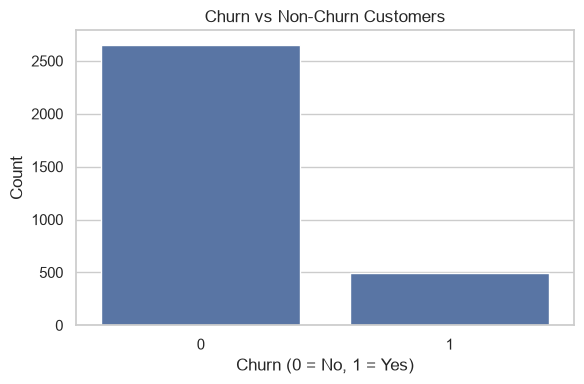

In [70]:
#data visualization
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="Churn")

plt.title("Churn vs Non-Churn Customers")
plt.xlabel("Churn (0 = No, 1 = Yes)")
plt.ylabel("Count")

plt.tight_layout()
plt.show()


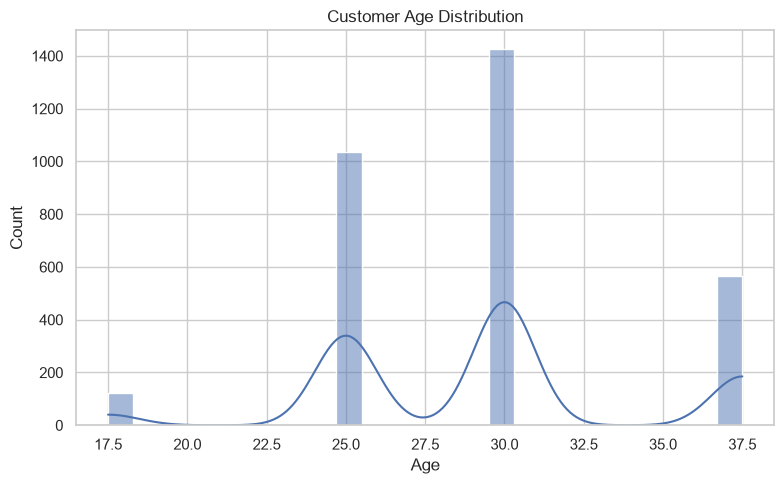

In [71]:
#Customer Age Distribution
plt.figure(figsize=(8, 5))
sns.histplot(data=df, x="Age", bins=25, kde=True)

plt.title("Customer Age Distribution")
plt.xlabel("Age")
plt.ylabel("Count")

plt.tight_layout()
plt.show()

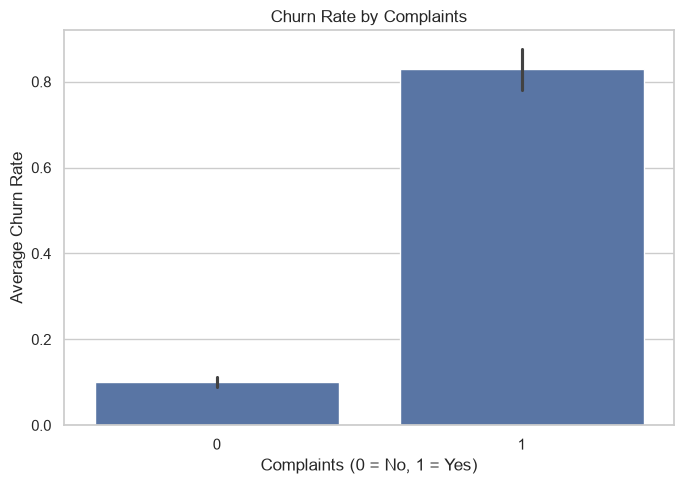

In [72]:
#churn rates by complains
plt.figure(figsize=(7, 5))
sns.barplot(data=df, x="Complains", y="Churn")

plt.title("Churn Rate by Complaints")
plt.xlabel("Complaints (0 = No, 1 = Yes)")
plt.ylabel("Average Churn Rate")

plt.tight_layout()
plt.show()

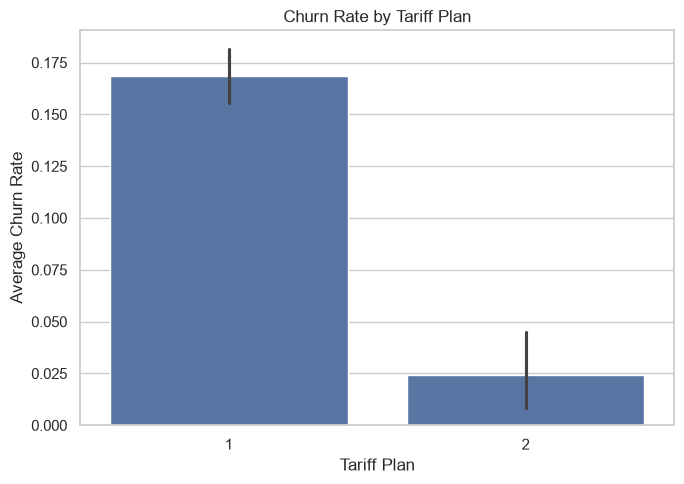

In [73]:
#churn rate by tarrif plan
plt.figure(figsize=(7, 5))
sns.barplot(data=df, x="Tariff_Plan", y="Churn")

plt.title("Churn Rate by Tariff Plan")
plt.xlabel("Tariff Plan")
plt.ylabel("Average Churn Rate")

plt.tight_layout()
plt.show()

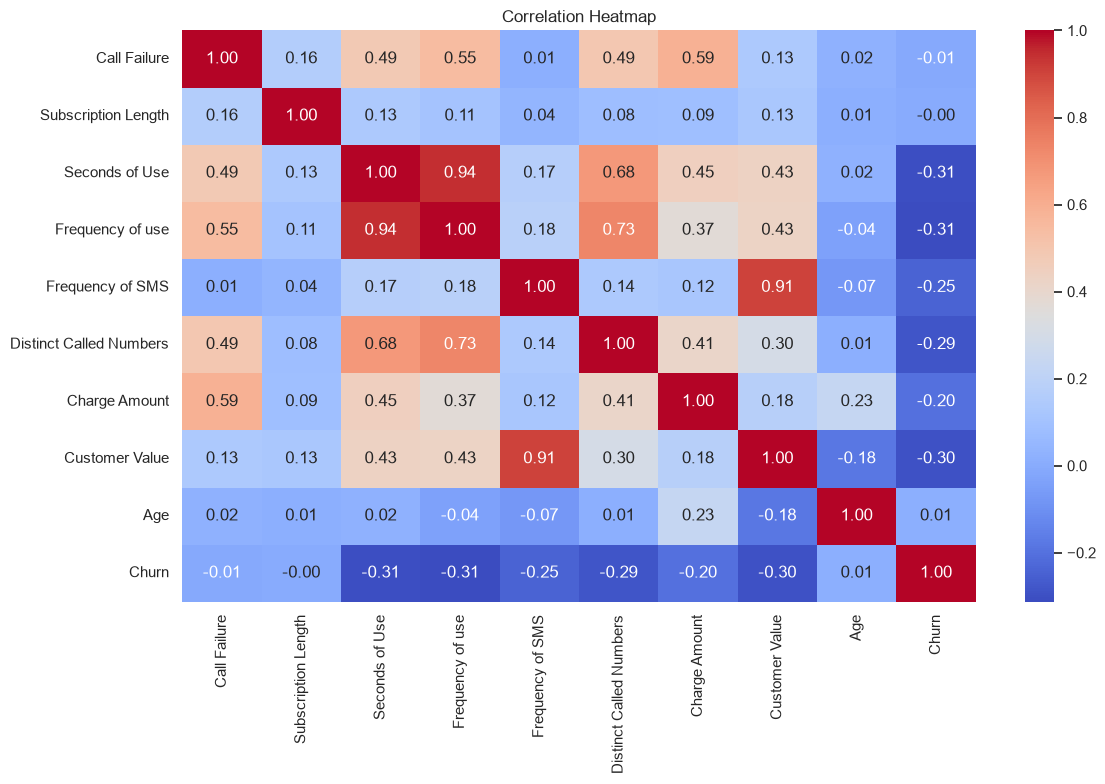

In [53]:
# Visualization 6: Correlation Heatmap

correlation_columns = [
    "Call Failure",
    "Subscription Length",
    "Seconds of Use",
    "Frequency of use",
    "Frequency of SMS",
    "Distinct Called Numbers",
    "Charge Amount",
    "Customer Value",
    "Age",
    "Churn"
]

correlation_columns = [
    column for column in correlation_columns
    if column in df.columns
]

plt.figure(figsize=(12, 8))

sns.heatmap(
    df[correlation_columns].corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()


In [54]:

# Rename columns for consistency

df = df.rename(columns={
    "Frequency of use": "Frequency_of_use",
    "Frequency of SMS": "Frequency_of_SMS",
    "Distinct Called Numbers": "Distinct_Called_Numbers",
    "Subscription Length": "Subscription_Length",
    "Customer Value": "Customer_Value",
    "Call Failure": "Call_Failure",
    "Charge Amount": "Charge_Amount",
    "Age Group": "Age_Group",
    "Tariff Plan": "Tariff_Plan"
})

# Update X and y if they have already been created
X = X.rename(columns={
    "Frequency of use": "Frequency_of_use",
    "Frequency of SMS": "Frequency_of_SMS",
    "Distinct Called Numbers": "Distinct_Called_Numbers",
    "Subscription Length": "Subscription_Length",
    "Customer Value": "Customer_Value",
    "Call Failure": "Call_Failure",
    "Charge Amount": "Charge_Amount",
    "Age Group": "Age_Group",
    "Tariff Plan": "Tariff_Plan"
})

y.name = "Churn"

print("Updated column names:")
print(df.columns.tolist())


Updated column names:
['Call_Failure', 'Complains', 'Subscription_Length', 'Charge_Amount', 'Seconds of Use', 'Frequency_of_use', 'Frequency_of_SMS', 'Distinct_Called_Numbers', 'Age_Group', 'Tariff_Plan', 'Status', 'Age', 'Customer_Value', 'Churn']


In [55]:

# Split dataset into training and testing sets

from sklearn.model_selection import train_test_split

RANDOM_STATE = 42

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True).round(3))

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True).round(3))


Training features: (2520, 13)
Testing features: (630, 13)

Training target distribution:
Churn
0    0.843
1    0.157
Name: proportion, dtype: float64

Testing target distribution:
Churn
0    0.843
1    0.157
Name: proportion, dtype: float64


In [56]:

# Data Preprocessing using Pipeline and ColumnTransformer

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer

# Identify numerical features
numeric_features = X_train.select_dtypes(
    include="number"
).columns.tolist()

# Identify categorical features
categorical_features = [
    column for column in categorical_columns
    if column in X_train.columns
]

# Remove categorical columns from numerical features
numeric_features = [
    column for column in numeric_features
    if column not in categorical_features
]

# Numerical preprocessing
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

# Combine preprocessing steps
preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", numeric_transformer, numeric_features),
        ("categorical", categorical_transformer, categorical_features)
    ],
    remainder="drop"
)

print("Numerical features:", numeric_features)
print("Categorical features:", categorical_features)


Numerical features: ['Call_Failure', 'Subscription_Length', 'Charge_Amount', 'Seconds of Use', 'Frequency_of_use', 'Frequency_of_SMS', 'Distinct_Called_Numbers', 'Age_Group', 'Tariff_Plan', 'Age', 'Customer_Value']
Categorical features: ['Complains', 'Status']


In [57]:
selector = SelectKBest(score_func=f_classif, k=20)

X_new = selector.fit_transform(X, y)

In [59]:

from sklearn.feature_selection import SelectKBest, f_classif

# Separate features and target
X = df.drop('Churn', axis=1)
y = df['Churn']

# Apply SelectKBest
selector = SelectKBest(score_func=f_classif, k=10)

X_new = selector.fit_transform(X, y)

# Get selected feature names
selected_features = X.columns[selector.get_support()]

# Display output
print("Selected Features:")
print(selected_features)


Selected Features:
Index(['Complains', 'Charge_Amount', 'Seconds of Use', 'Frequency_of_use',
       'Frequency_of_SMS', 'Distinct_Called_Numbers', 'Age_Group',
       'Tariff_Plan', 'Status', 'Customer_Value'],
      dtype='str')


In [60]:

# Display Feature Selection Scores

feature_scores = pd.DataFrame({
    'Feature': X.columns,
    'Score': selector.scores_,
    'Selected': selector.get_support()
})

feature_scores = feature_scores.sort_values(
    by='Score',
    ascending=False
)

print("Feature Selection Scores:")
print(feature_scores)


Feature Selection Scores:
                    Feature        Score  Selected
1                 Complains  1243.008144      True
10                   Status  1043.614075      True
5          Frequency_of_use   341.587481      True
4            Seconds of Use   326.259271      True
12           Customer_Value   300.200515      True
7   Distinct_Called_Numbers   278.374658      True
6          Frequency_of_SMS   202.748690      True
3             Charge_Amount   134.337747      True
9               Tariff_Plan    35.672560      True
8                 Age_Group     0.666598      True
11                      Age     0.612481     False
0              Call_Failure     0.272934     False
2       Subscription_Length     0.026825     False


In [61]:

# Split dataset into training and testing sets

from sklearn.model_selection import train_test_split

RANDOM_STATE = 42

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Training set:", X_train.shape)
print("Testing set:", X_test.shape)

print("\nTraining target proportions:")
print(y_train.value_counts(normalize=True).round(3))

print("\nTesting target proportions:")
print(y_test.value_counts(normalize=True).round(3))


Training set: (2520, 13)
Testing set: (630, 13)

Training target proportions:
Churn
0    0.843
1    0.157
Name: proportion, dtype: float64

Testing target proportions:
Churn
0    0.843
1    0.157
Name: proportion, dtype: float64


In [62]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.fit_transform(X_test)

In [64]:
# Selecting Algorithm 
models = {
    "Logistic Regression": LogisticRegression(),
    "Decision Tree": DecisionTreeClassifier(),
    "Random Forest": RandomForestClassifier(n_estimators=100),
}


In [65]:

# Model Evaluation

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    f1_score,
    recall_score
)

# Store results
scores = []

for name, model in models.items():

    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)

    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred, zero_division=0)
    f1 = f1_score(y_test, y_pred, zero_division=0)
    recall = recall_score(y_test, y_pred, zero_division=0)

    scores.append({
        "Model": name,
        "Accuracy": round(accuracy, 2),
        "Precision": round(precision, 2),
        "F1 Score": round(f1, 2),
        "Recall": round(recall, 2)
    })

# Convert to DataFrame for display
results_df = pd.DataFrame(scores)

print("Model Performance Comparison:")
print(results_df)


Model Performance Comparison:
                 Model  Accuracy  Precision  F1 Score  Recall
0  Logistic Regression      0.86       0.58      0.45    0.37
1        Decision Tree      0.94       0.83      0.79    0.75
2        Random Forest      0.96       0.91      0.86    0.81
